In [1]:
import numpy as np 
import pandas as pd 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
%pip install scikit-learn==1.8.0
import sklearn
import matplotlib

print(np.__version__)
print(pd.__version__)
print(sklearn.__version__)
print(matplotlib.__version__)
print(sns.__version__)


1.26.4
2.2.2
1.8.0
3.9.2
0.13.2


In [3]:
df = pd.read_csv('breast cancer.csv')

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
df = df.dropna(axis=1, how='all')

In [6]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

In [7]:
if df['diagnosis'].isnull().any():
    df['diagnosis'] = df['diagnosis'].fillna(df['diagnosis'].mode()[0])

In [8]:
df['diagnosis'] = df['diagnosis'].map({'M': 0, 'B': 1})

print("Cleaning Complete. No missing values left.")

Cleaning Complete. No missing values left.


In [9]:
corr_matrix = df.corr()

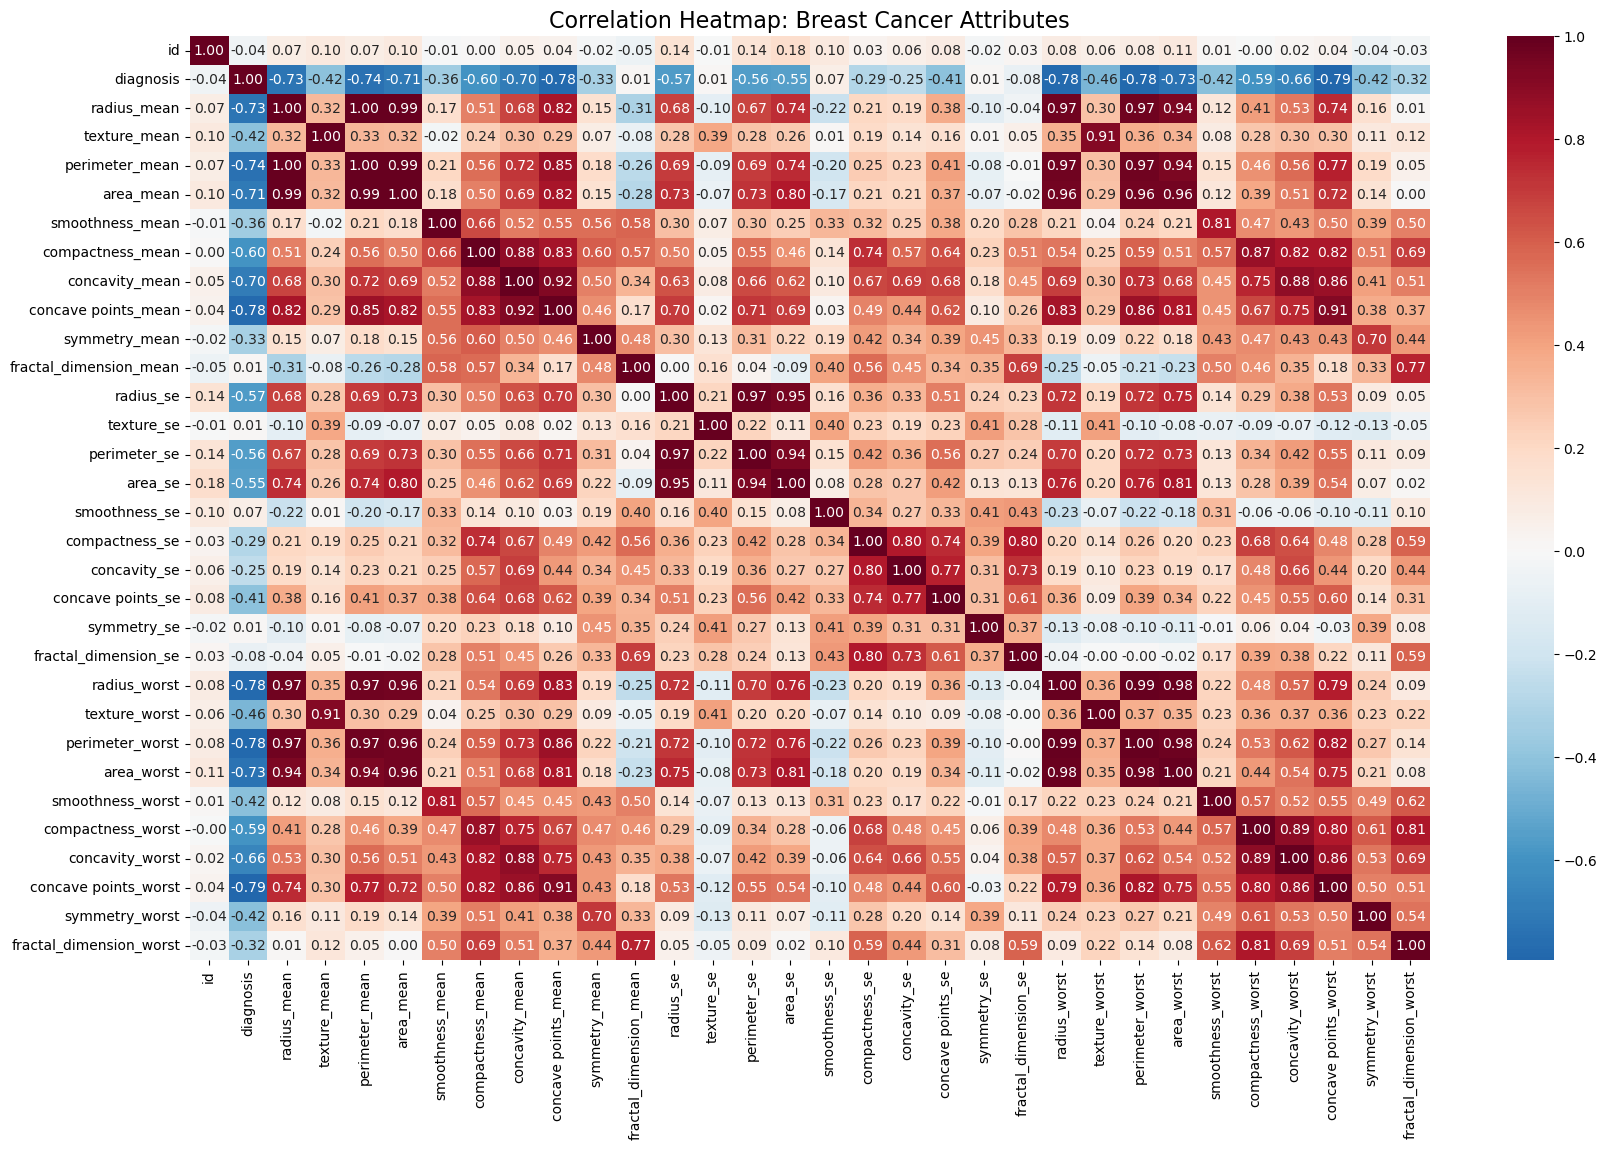

In [10]:
plt.figure(figsize=(20,12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='RdBu_r', center=0)
plt.title("Correlation Heatmap: Breast Cancer Attributes", fontsize=16)
plt.show()

In [11]:
diag_corr = corr_matrix['diagnosis'].abs().sort_values(ascending=False)
print("Top 10 Attributes most correlated with Diagnosis:")
print(diag_corr.head(11))

Top 10 Attributes most correlated with Diagnosis:
diagnosis               1.000000
concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
area_worst              0.733825
radius_mean             0.730029
area_mean               0.708984
concavity_mean          0.696360
concavity_worst         0.659610
Name: diagnosis, dtype: float64


#EDA


## Let's look at 'worst perimeter' since it's a strong indicator

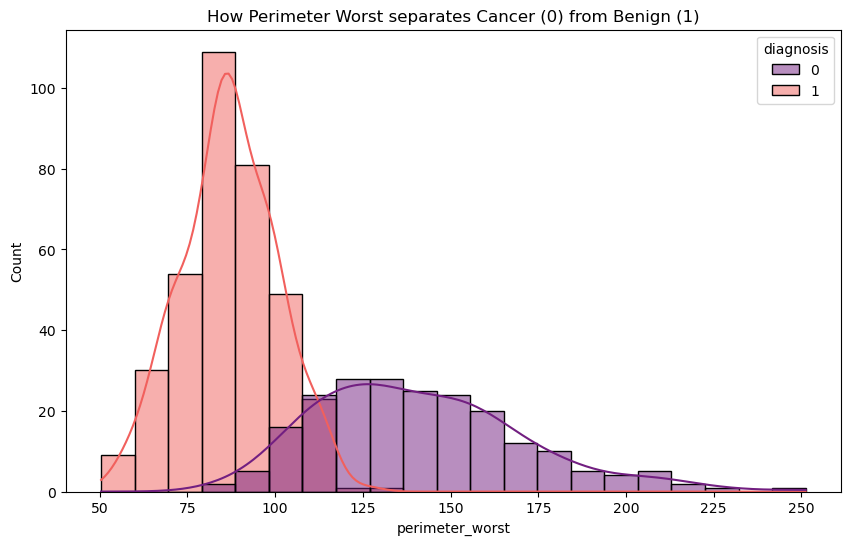

In [12]:

plt.figure(figsize=(10,6))
sns.histplot(data=df, x='perimeter_worst', hue='diagnosis', kde=True, palette='magma')
plt.title('How Perimeter Worst separates Cancer (0) from Benign (1)')
plt.show()

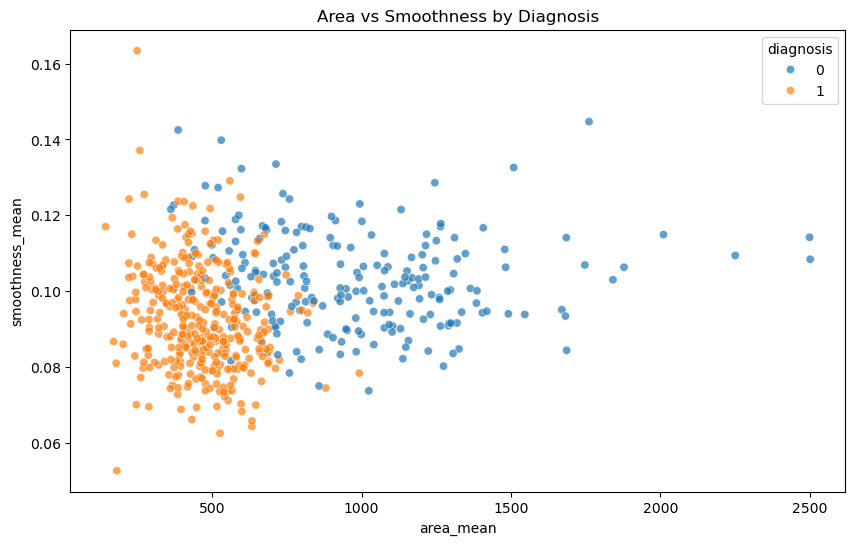

In [13]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='area_mean', y='smoothness_mean', hue='diagnosis', data=df, alpha=0.7)
plt.title('Area vs Smoothness by Diagnosis')
plt.show()

#DATA SCALING#

Scaling turns "Raw Measurements" into "Performance Ranks." It ensures we don't ignore the small details just because the big numbers are easier to see.

Now that the data is scaled and "fair," would you like to see the code to perform a "Train-Test Split" to prepare for the actual exam-style prediction?

In [26]:
from sklearn.preprocessing import StandardScaler
import joblib

In [27]:
features_list = ['concave points_mean', 'area_worst', 'radius_worst', 'perimeter_worst']

In [38]:
X_train_4 = X_train[features_list]
X_test_4 = X_test[features_list]

In [39]:
scaler_4 = StandardScaler()
X_train_scaled = scaler_4.fit_transform(X_train_4)
X_test_scaled = scaler_4.transform(X_test_4)

#training and testing 


In [42]:
from sklearn.model_selection import train_test_split

# X = Our scaled features (measurements)
# y = Our target (diagnosis: 0 or 1)
# X_train_scaled is the scaled features for the training rows (455 samples).
# Convert it back to a DataFrame aligned to y_train indices so lengths match.
X = pd.DataFrame(X_train_scaled, columns=features_list, index=X_train.index)
y = y_train

# We split the data: 80% for training, 20% for testing
# random_state=42 ensures reproducible splits
X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(X, y, test_size=0.2, random_state=42)



In [43]:
print(f"Total samples: {len(X)}")
print(f"Training set size: {len(X_train_4)}")
print(f"Testing set size: {len(X_test_4)}")

Total samples: 455
Training set size: 364
Testing set size: 91


In [44]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [45]:
# Ensure train/test split exists; if not, create it from X and y
try:
	X_train_4  # verify variable exists
	y_train_4
except NameError:
	from sklearn.model_selection import train_test_split
	# ensure X and y are available
	if 'X' not in globals():
		X = X_train_scaled
	if 'y' not in globals():
		y = df['diagnosis']
	X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(X, y, test_size=0.2, random_state=42)

model_full = RandomForestClassifier(n_estimators=100, random_state=42)
model_full.fit(X_train_4, y_train_4)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [34]:
importances = pd.Series(model_full.feature_importances_, index=X_train.columns)
top_4_features = importances.nlargest(4).index.tolist()
print(f"Your 4 main inputs are: {top_4_features}")

Your 4 main inputs are: ['perimeter_worst', 'area_worst', 'concave points_worst', 'radius_worst']


In [46]:
model_final = RandomForestClassifier(n_estimators=100, random_state=42)
model_final.fit(X_train_4, y_train_4)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [37]:
from sklearn.metrics import confusion_matrix

# generate predictions for the selected test set
y_pred_test_4 = model_final.predict(X_test_4)

plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test_4, y_pred_test_4), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Predicting Malignancy')
plt.show()

NameError: name 'confusion_matrix' is not defined

<Figure size 600x400 with 0 Axes>

In [ ]:
import joblib

# 1. Save the trained Random Forest model
joblib.dump(model_final, 'breast_cancer_model.pkl')

# 2. Save the scaler (StandardScaler or MinMaxScaler)
joblib.dump(scaler, 'feature_scaler.pkl')

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!
